### Tests of the channels

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import c, pi

from utils.utils import *
from components.ris import RIS
from components.antenna import Antenna
from channels.tx_ris_rx_channel import tx_ris_rx_channel

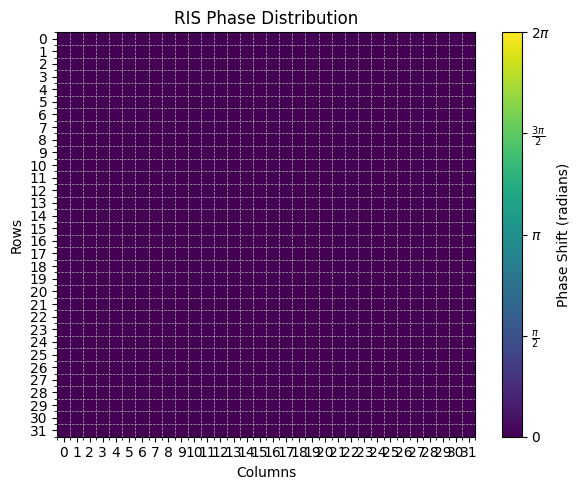

In [2]:
# Create RIS
f = 28e9
lam = c/f

ris = RIS(center=[0,0,0],boresight='z',Ncol=32,Nrow=32,delta_h=lam/2,delta_v=lam/2,dx=0.47*lam,dy=0.47*lam,fc=f,radiation_factor=1,phase_shifts_dict={"0": 0,"1": pi},att_dict={"0": 1,"1": 1})

ris.plot_phase_dist()

In [3]:
# Create antennas and channel
tx_pos = sph2cart([10.01,0,0])
rx_pos = sph2cart([11,180,30])

tx_antenna = Antenna(tx_pos,0)
rx_antenna = Antenna(rx_pos,0)

channel = tx_ris_rx_channel(tx_antenna=tx_antenna,rx_antenna=rx_antenna,ris=ris,optimizer='direct_disc')

ris2 = ris.copy()
channel_perf = tx_ris_rx_channel(tx_antenna=tx_antenna,rx_antenna=rx_antenna,ris=ris2, mode='perfect')

ris3 = ris.copy()
channel_maxbf = tx_ris_rx_channel(tx_antenna=tx_antenna,rx_antenna=rx_antenna,ris=ris3,optimizer='max_bf')


Previous state of perfect RIS:


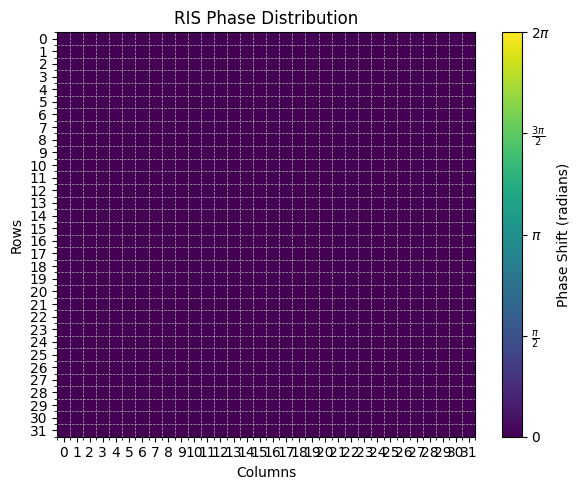

Optimized state of perfect RIS:


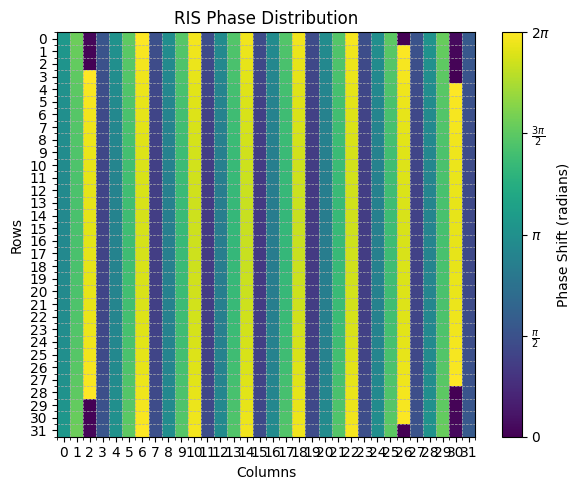

Previous state of normal RIS (direct dic. alg.):


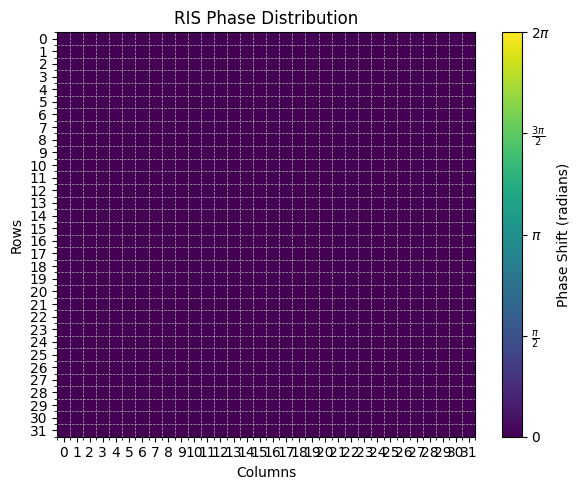

Optimized state of normal RIS (direct dic. alg.):


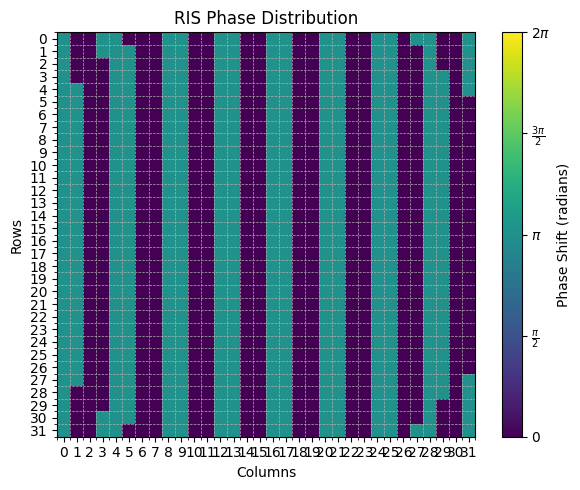

Previous state of normal RIS (max bf alg.):


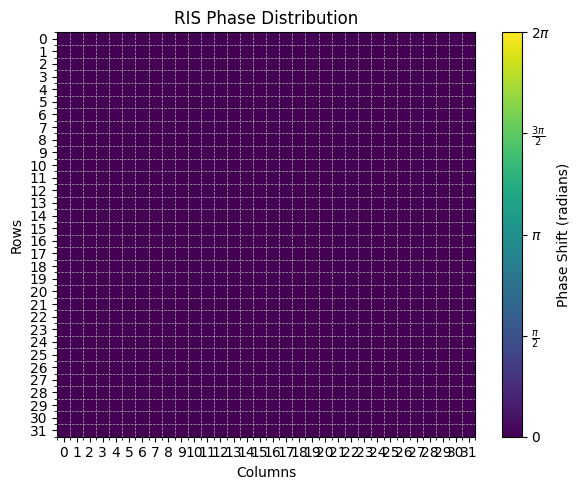

Optimum value of α: 2.100 rad
Optimized state of normal RIS (max bf alg.):


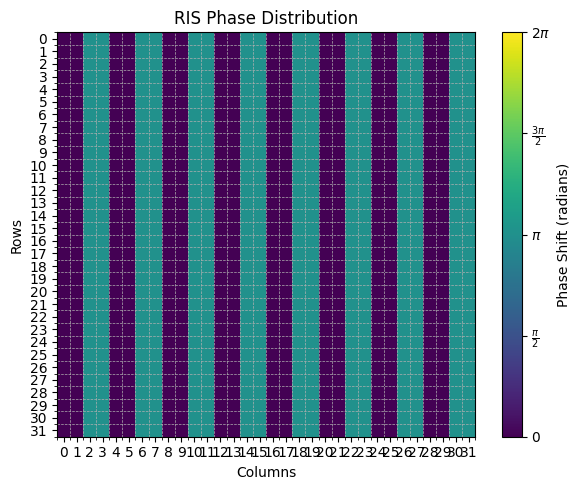

In [4]:
# Optimize channel and see the return
print("Previous state of perfect RIS:")
ris2.plot_phase_dist()

channel_perf.optimize()

print("Optimized state of perfect RIS:")
ris2.plot_phase_dist()

print("Previous state of normal RIS (direct dic. alg.):")
ris.plot_phase_dist()

channel.optimize()

print("Optimized state of normal RIS (direct dic. alg.):")
ris.plot_phase_dist()

print("Previous state of normal RIS (max bf alg.):")
ris3.plot_phase_dist()

channel_maxbf.optimize()

print("Optimized state of normal RIS (max bf alg.):")
ris3.plot_phase_dist()


Beamforming normalized at RX location with perfect shifts: 1.000


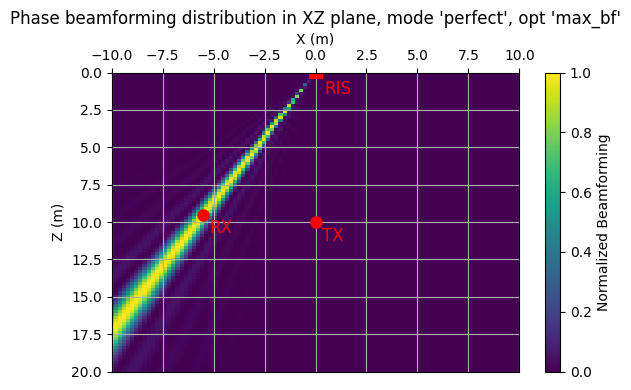

Beamforming normalized at RX location with direct discretization shifts: 0.454


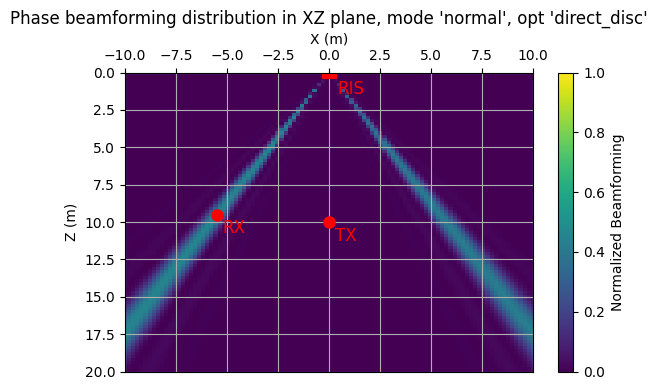

Beamforming normalized at RX location with max bf discretization shifts: 0.487


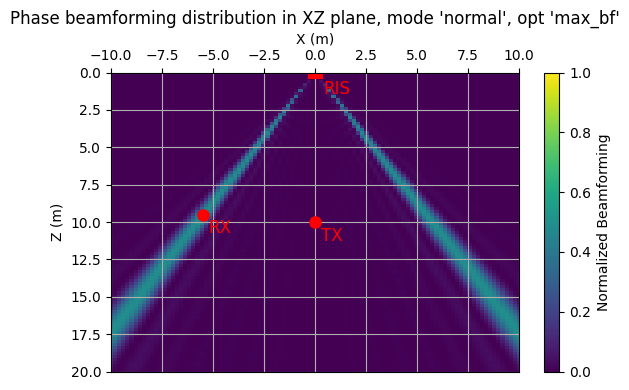

In [5]:
# Try phase beamforming function:

# Generate rx locations as a 2D map
xlim = [-10, 10]
zlim = [0, 20]
Nx = 100
Nz = 100

maximum_bf = (ris.Nrow * ris.Ncol)**2

print(f"Beamforming normalized at RX location with perfect shifts: {channel_perf.phase_bf_multrx(rx_pos[0])[0] / maximum_bf:.3f}")
channel_perf.plot_phase_bf_2d_map(ax1lim=xlim,ax2lim=zlim,Nax1=Nx,Nax2=Nz,plane='xz')

print(f"Beamforming normalized at RX location with direct discretization shifts: {channel.phase_bf_multrx(rx_pos[0])[0] / maximum_bf:.3f}")
channel.plot_phase_bf_2d_map(ax1lim=xlim,ax2lim=zlim,Nax1=Nx,Nax2=Nz,plane='xz')

print(f"Beamforming normalized at RX location with max bf discretization shifts: {channel_maxbf.phase_bf_multrx(rx_pos[0])[0] / maximum_bf:.3f}")
channel_maxbf.plot_phase_bf_2d_map(ax1lim=xlim,ax2lim=zlim,Nax1=Nx,Nax2=Nz,plane='xz')

Path gain at RX location with perfect shifts: -95.169 dB


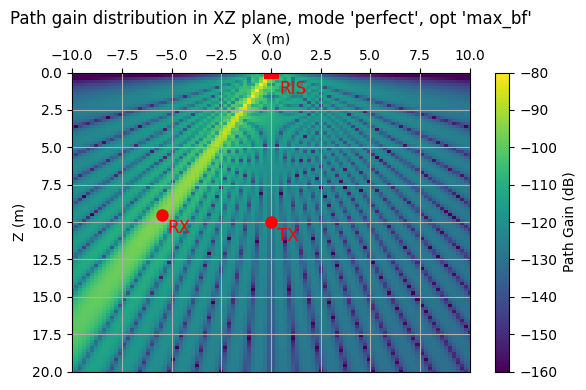

Path gain at RX location with direct disc. shifts: -98.598 dB


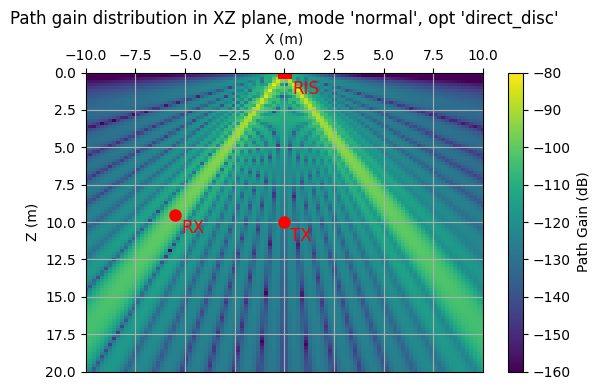

Path gain at RX location with max bf disc. shifts: -98.294 dB


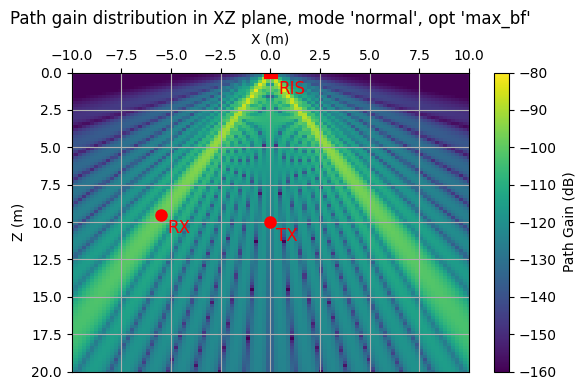

In [6]:
# Try path gain function:

# Generate rx locations as a 2D map
xlim = [-10, 10]
zlim = [0, 20]
Nx = 100
Nz = 100
vmin = -160
vmax = -80

print(f"Path gain at RX location with perfect shifts: {10*np.log10(channel_perf.path_gain_multrx(rx_pos[0])[0]):.3f} dB")
channel_perf.plot_path_gain_2d_map(ax1lim=xlim,ax2lim=zlim,Nax1=Nx,Nax2=Nz,plane='xz',vmin=vmin,vmax=vmax)

print(f"Path gain at RX location with direct disc. shifts: {10*np.log10(channel.path_gain_multrx(rx_pos[0])[0]):.3f} dB")
channel.plot_path_gain_2d_map(ax1lim=xlim,ax2lim=zlim,Nax1=Nx,Nax2=Nz,plane='xz',vmin=vmin,vmax=vmax)

print(f"Path gain at RX location with max bf disc. shifts: {10*np.log10(channel_maxbf.path_gain_multrx(rx_pos[0])[0]):.3f} dB")
channel_maxbf.plot_path_gain_2d_map(ax1lim=xlim,ax2lim=zlim,Nax1=Nx,Nax2=Nz,plane='xz',vmin=vmin,vmax=vmax)

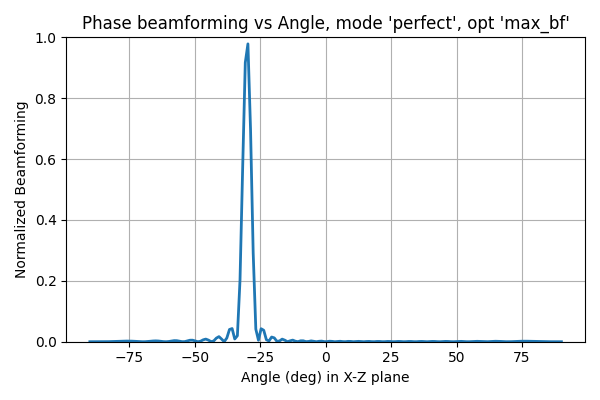

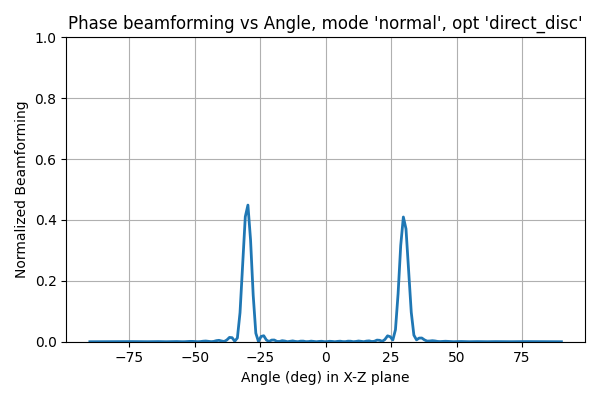

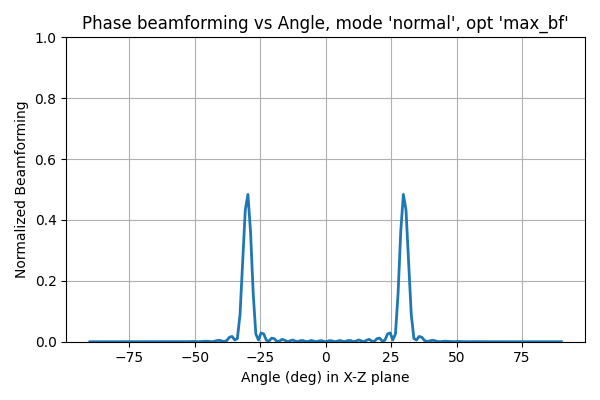

In [7]:
%matplotlib widget

channel_perf.plot_phase_bf_angle(r=11,Nr=180,axis='x')

channel.plot_phase_bf_angle(r=11,Nr=180,axis='x')

channel_maxbf.plot_phase_bf_angle(r=11,Nr=180,axis='x')

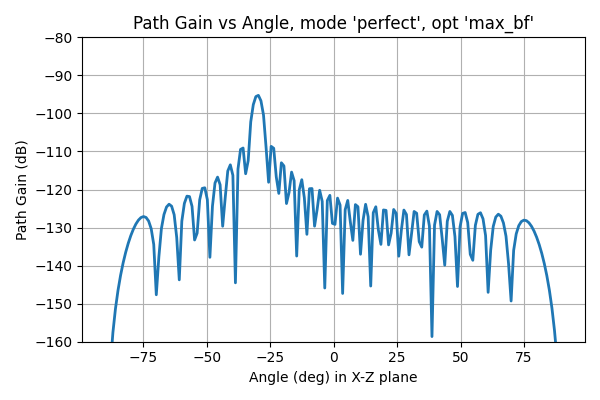

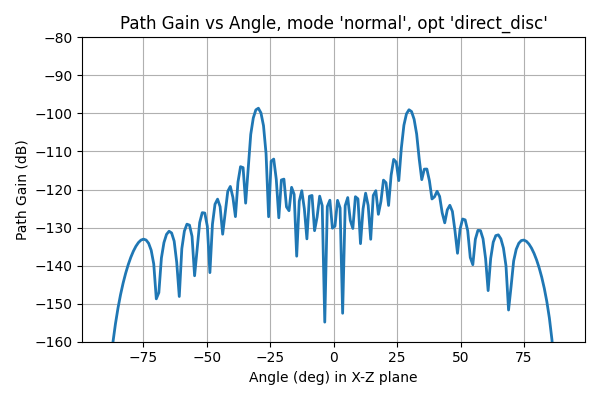

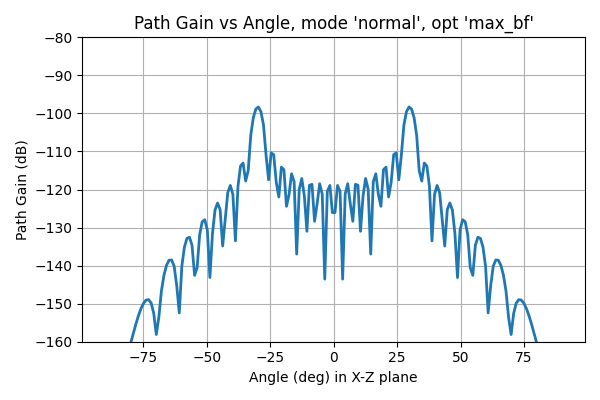

In [8]:
%matplotlib widget

channel_perf.plot_path_gain_angle(r=11,Nr=180,axis='x',vmin=vmin,vmax=vmax)

channel.plot_path_gain_angle(r=11,Nr=180,axis='x',vmin=vmin,vmax=vmax)

channel_maxbf.plot_path_gain_angle(r=11,Nr=180,axis='x',vmin=vmin,vmax=vmax)